# 9 — Compare four models on the same untouched Test set


## Configuration and metrics


In [8]:
from pathlib import Path
import json, hashlib, random, time, copy, platform, importlib.metadata, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

VERSION_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'benchmark_config.json').is_file())
CONFIG = json.loads((VERSION_ROOT / 'benchmark_config.json').read_text(encoding='utf-8'))
RAW = Path(CONFIG['raw_directory'])
if not RAW.is_absolute():
    RAW = (VERSION_ROOT / RAW).resolve()
DATA = VERSION_ROOT / 'dataset/processed'
ARTIFACTS = VERSION_ROOT / 'model/artifacts'
REPORTS = VERSION_ROOT / 'model/reports'
CLASSES = CONFIG['classes']
N_CLASSES = len(CLASSES)
SEED = CONFIG['seed']
FS = 360
LEFT, RIGHT = CONFIG['left_samples'], CONFIG['right_samples']
WAVE_LENGTH = LEFT + RIGHT + 1
ALL_SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
ALL_LABEL_MAP = {s: i for i, symbols in enumerate(ALL_SYMBOLS) for s in symbols}
if CLASSES != ['N', 'S', 'V', 'F'] or LEFT < 18 or RIGHT < 180 or not CONFIG['offline_context']:
    raise ValueError('This version requires N/S/V/F, at least 50 ms before / 500 ms after FP, and offline context')

def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; รัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def macro_f1(y, predicted):
    return float(f1_score(y, predicted, labels=list(range(N_CLASSES)), average='macro', zero_division=0))

def class_weights(y, power=0.5, cap=20.0):
    counts = np.bincount(np.asarray(y, dtype=int), minlength=N_CLASSES)
    if (counts == 0).any():
        raise ValueError('Training data must contain all configured classes')
    values = np.minimum((len(y) / (N_CLASSES * counts)) ** power, cap)
    return values / np.average(values, weights=counts)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
    except ImportError:
        pass

def environment():
    names = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'wfdb', 'pyarrow',
             'PyWavelets', 'xgboost', 'torch', 'optuna']
    versions = {}
    for name in names:
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = 'not installed'
    return {'python': platform.python_version(), 'platform': platform.platform(), 'packages': versions}

def validate_partitions(frame):
    if set(frame.split) != {'train', 'validation', 'test'}:
        raise ValueError('Require train, validation and test')
    if frame.beat_id.duplicated().any() or frame.groupby('patient_group').split.nunique().max() != 1:
        raise ValueError('Duplicate beat or patient leakage')
    for name, part in frame.groupby('split'):
        if set(part.class_id) != set(range(N_CLASSES)):
            raise ValueError(f'{name}: missing class')
    paired = frame.loc[frame.record_id.isin(['201', '202'])]
    if paired.patient_group.nunique() != 1 or paired.split.nunique() != 1:
        raise ValueError('201 and 202 must remain in one patient group and one partition')

def load_partition(split, *, allow_test=False):
    if split == 'test' and not allow_test:
        raise PermissionError('Test is evaluated only in notebook 9')
    manifest = read_json(DATA / 'prepared.json')
    if manifest['config_hash'] != sha256(VERSION_ROOT / 'benchmark_config.json'):
        raise ValueError('Configuration changed; rerun notebooks 1-4')
    for upstream in ['audit.json', 'split.json', 'preprocessing.json', 'feature_schema.json',
                     'inventory.parquet', 'split_inventory.parquet']:
        if sha256(DATA / upstream) != manifest['files'][upstream]:
            raise ValueError(f'Upstream artifact changed: {upstream}; rerun preparation')
    folder = DATA / split
    values = {}
    for key, name in [('meta', 'metadata.parquet'), ('wave', 'waveforms.npy'),
                      ('rr', 'rr.npy'), ('x', 'features_raw.npy')]:
        if sha256(folder / name) != manifest['files'][f'{split}/{name}']:
            raise ValueError(f'Artifact changed: {split}/{name}; rerun preparation')
        values[key] = pd.read_parquet(folder / name) if key == 'meta' else np.load(folder / name)
    m = values['meta']
    if not all(len(v) == len(m) for v in values.values()):
        raise ValueError('Array lengths differ')
    if not np.array_equal(m.waveform_index, np.arange(len(m))) or not m.split.eq(split).all():
        raise ValueError('Array/metadata alignment failed')
    if values['wave'].shape != (len(m), 2, WAVE_LENGTH) or not np.isfinite(values['wave']).all():
        raise ValueError('Invalid waveform shape or nonfinite waveform')
    values['y'] = m.class_id.to_numpy(dtype=np.int64)
    return values

def concatenate_partitions(parts):
    return {key: pd.concat([p[key] for p in parts], ignore_index=True) if key == 'meta'
            else np.concatenate([p[key] for p in parts]) for key in parts[0]}

def fit_transforms(part):
    feature_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    rr_imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    rr_scaler = RobustScaler(quantile_range=(10., 90.))
    feature_imputer.fit(part['x'])
    rr_scaler.fit(rr_imputer.fit_transform(part['rr']))
    return {'feature_imputer': feature_imputer, 'rr_imputer': rr_imputer, 'rr_scaler': rr_scaler}

def transform_partition(part, transforms):
    result = dict(part)
    result['x'] = transforms['feature_imputer'].transform(part['x']).astype(np.float32)
    filled = transforms['rr_imputer'].transform(part['rr'])
    scaled = transforms['rr_scaler'].transform(filled)
    # Clipping bounds are fixed protocol constants; missing flags keep edge information.
    result['context'] = np.column_stack([np.clip(scaled, -10., 10.),
                                        ~np.isfinite(part['rr'])]).astype(np.float32)
    if not np.isfinite(result['x']).all() or not np.isfinite(result['context']).all():
        raise ValueError('Imputation/scaling produced nonfinite input')
    return result

def prepare_training(train_raw, validation_raw):
    transforms = fit_transforms(train_raw)
    return transform_partition(train_raw, transforms), transform_partition(validation_raw, transforms), transforms

def metrics(y, pred):
    report = classification_report(y, pred, labels=list(range(N_CLASSES)), target_names=CLASSES,
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(y, pred, labels=list(range(N_CLASSES)))
    normalized = np.divide(matrix, matrix.sum(1, keepdims=True), out=np.zeros_like(matrix, dtype=float),
                           where=matrix.sum(1, keepdims=True) != 0)
    return {'accuracy': float(accuracy_score(y, pred)), 'macro_f1': macro_f1(y, pred),
            'weighted_f1': float(report['weighted avg']['f1-score']),
            'balanced_accuracy': float(normalized.diagonal().mean()), 'per_class': report,
            'confusion_matrix': matrix.tolist(), 'normalized_confusion_matrix': normalized.tolist()}

def plot_trials(study, destination):
    frame = study.trials_dataframe()
    frame.to_csv(destination / 'trials.csv', index=False)
    complete = frame.loc[frame.state.eq('COMPLETE')].copy()
    if len(complete):
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.plot(complete.number, complete.value, 'o-', alpha=.6, label='Validation Macro-F1')
        ax.plot(complete.number, complete.value.cummax(), linewidth=2, label='Best so far')
        ax.set(xlabel='Trial', ylabel='Macro-F1', ylim=(0, 1), title=study.study_name)
        ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
        fig.savefig(destination / 'tuning.png', dpi=160)
        plt.show(); plt.close(fig)


In [9]:
import torch
CPU_THREADS=max(1,min(8,(os.cpu_count() or 2)-1))
DL_DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
LATENCY_REPEATS=20
BOOTSTRAP_REPEATS=1000


## Saved model architecture and prediction


In [10]:
import torch
from torch import nn
from torch.nn import functional as F
class ResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels, kernel, stride=1):
        super().__init__()
        self.main = nn.Sequential(nn.Conv1d(in_channels, out_channels, kernel, stride=stride, padding=kernel // 2, bias=False), nn.BatchNorm1d(out_channels), nn.ReLU(), nn.Conv1d(out_channels, out_channels, kernel, padding=kernel // 2, bias=False), nn.BatchNorm1d(out_channels))
        self.skip = nn.Identity() if in_channels == out_channels and stride == 1 else nn.Sequential(nn.Conv1d(in_channels, out_channels, 1, stride=stride, bias=False), nn.BatchNorm1d(out_channels))

    def forward(self, x):
        return F.relu(self.main(x) + self.skip(x))

class ECGNetwork(nn.Module):

    def __init__(self, kind, parameters, context_dim, n_classes=N_CLASSES):
        super().__init__()
        layers, previous = ([], 2)
        for stage in range(parameters['stages']):
            width = min(parameters['base_channels'] * 2 ** stage, 256)
            for block in range(parameters['blocks_per_stage']):
                layers.append(ResidualBlock(previous, width, parameters['kernel'], stride=2 if block == 0 else 1))
                previous = width
        self.conv = nn.Sequential(*layers)
        self.kind = kind
        if kind == 'cnn_bilstm':
            hidden = parameters['lstm_hidden']
            self.lstm = nn.LSTM(previous, hidden, num_layers=parameters['lstm_layers'], batch_first=True, bidirectional=True, dropout=parameters['dropout'] if parameters['lstm_layers'] > 1 else 0.0)
            previous = 2 * hidden
        self.rr_branch = nn.Sequential(nn.Linear(context_dim, parameters['rr_hidden']), nn.LayerNorm(parameters['rr_hidden']), nn.ReLU())
        combined = 2 * previous + parameters['rr_hidden']
        self.head = nn.Sequential(nn.Linear(combined, parameters['head_hidden']), nn.LayerNorm(parameters['head_hidden']), nn.ReLU(), nn.Dropout(parameters['dropout']), nn.Linear(parameters['head_hidden'], n_classes))

    def forward(self, waveform, context):
        encoded = self.conv(waveform)
        if self.kind == 'cnn_bilstm':
            encoded, _ = self.lstm(encoded.transpose(1, 2))
            encoded = encoded.transpose(1, 2)
        pooled = torch.cat([encoded.mean(2), encoded.amax(2)], dim=1)
        return self.head(torch.cat([pooled, self.rr_branch(context)], dim=1))

def predict_probabilities(model, part, batch_size=256):
    model.eval()
    device = next(model.parameters()).device
    result = []
    with torch.inference_mode():
        for start in range(0, len(part['y']), batch_size):
            wave = torch.as_tensor(part['wave'][start:start + batch_size], device=device)
            context = torch.as_tensor(part['context'][start:start + batch_size], device=device)
            result.append(model(wave, context).softmax(1).cpu().numpy())
    return np.concatenate(result)


## Evaluation definitions


In [11]:
def plot_confusion_matrix(scores, model_name, *, normalized=False):
    # Stored metrics follow sklearn: rows=True, columns=Predicted.
    counts = np.asarray(scores['confusion_matrix'])
    if normalized:
        support = counts.sum(axis=1, keepdims=True)
        values = np.divide(counts, support, out=np.zeros_like(counts, dtype=float), where=support != 0)
    else:
        values = counts
    matrix = values.T  # Display rows=Predicted, columns=True.
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1 if normalized else None)
    threshold = 0.5 if normalized else matrix.max() / 2
    for predicted in range(N_CLASSES):
        for true in range(N_CLASSES):
            value = matrix[predicted, true]
            label = f'{value:.1%}' if normalized else f'{int(value):,}'
            ax.text(true, predicted, label, ha='center', va='center',
                    color='white' if value > threshold else 'black')
    mode = 'Normalized by true class' if normalized else 'Count'
    ax.set(xticks=range(N_CLASSES), yticks=range(N_CLASSES), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel='True', ylabel='Predicted', title=f'{model_name} ? {mode}')
    fig.colorbar(image, ax=ax, label='Fraction of true class' if normalized else 'Number of beats')
    fig.tight_layout()
    return fig

import torch
import xgboost as xgb
from torch import nn
from torch.nn import functional as F

def load_candidate(kind):
    selected = read_json(ARTIFACTS/kind/'selected.json')
    folder = ARTIFACTS/selected['path']/'final'
    info = read_json(folder/'info.json')
    if info['prepared_hash'] != sha256(DATA/'prepared.json') or info['classes'] != CLASSES:
        raise ValueError(f'{kind}: model/data/class mismatch')
    if info['selected_trial'] != read_json(ARTIFACTS/selected['path']/'validation_best/info.json')['trial']:
        raise ValueError(f'{kind}: rerun final refit after tuning')
    if kind == 'rf':
        model = joblib.load(folder/'model.joblib')
    elif kind == 'xgb':
        model = xgb.Booster(); model.load_model(folder/'model.ubj')
        model.set_param({'device':'cpu', 'nthread':CPU_THREADS})
    else:
        model = ECGNetwork(kind, info['parameters'], info['context_dim'])
        model.load_state_dict(torch.load(folder/'model.pt', map_location='cpu', weights_only=True))
        model = model.to(DL_DEVICE).eval()
    transforms = joblib.load(folder/'transforms.joblib')
    return model, transforms, info

def predict_candidate(model, kind, part, batch_size=256):
    if kind == 'rf':
        out = np.zeros((len(part['y']),N_CLASSES), dtype=np.float32)
        out[:,np.asarray(model.classes_, dtype=int)] = model.predict_proba(part['x'])
        return out
    if kind == 'xgb':
        return model.predict(xgb.DMatrix(part['x'], nthread=CPU_THREADS))
    return predict_probabilities(model, part, batch_size=batch_size)

def synchronize(kind):
    if kind in ['cnn','cnn_bilstm'] and str(DL_DEVICE).startswith('cuda'): torch.cuda.synchronize()

def latency(model, kind, part, repeats=20):
    output = {}
    for size in [1,128]:
        batch = {key:value[:size] for key,value in part.items()}
        actual = len(batch['y'])
        for _ in range(3): predict_candidate(model,kind,batch,batch_size=size)
        timings=[]
        for _ in range(repeats):
            synchronize(kind); start=time.perf_counter()
            predict_candidate(model,kind,batch,batch_size=size)
            synchronize(kind); timings.append((time.perf_counter()-start)*1000/actual)
        output[f'batch_{size}_ms_per_beat']=float(np.median(timings))
        output[f'batch_{size}_actual_count']=actual
    return output

def paired_patient_bootstrap(predictions, repeats=1000):
    reference=next(iter(predictions.values()))
    if any(not np.array_equal(frame.beat_id,reference.beat_id) for frame in predictions.values()):
        raise ValueError('Models have different test examples')
    groups=[np.flatnonzero(reference.patient_group.eq(group).to_numpy())
            for group in sorted(reference.patient_group.unique())]
    rng=np.random.default_rng(SEED)
    draws={kind:[] for kind in predictions}; missing=0
    for _ in range(repeats):
        indices=np.concatenate([groups[i] for i in rng.integers(0,len(groups),len(groups))])
        missing += reference.iloc[indices].class_id.nunique()<N_CLASSES
        for kind,frame in predictions.items():
            part=frame.iloc[indices]
            draws[kind].append(macro_f1(part.class_id,part.predicted))
    rows=[]
    for kind,values in draws.items():
        rows.append({'model':kind,'macro_f1_lower_95':float(np.quantile(values,.025)),
            'macro_f1_upper_95':float(np.quantile(values,.975)),
            'missing_class_fraction':missing/repeats,'replicates':repeats})
    differences=[]
    kinds=list(draws)
    for i,a in enumerate(kinds):
        for b in kinds[i+1:]:
            diff=np.array(draws[a])-np.array(draws[b])
            differences.append({'model_a':a,'model_b':b,'macro_f1_difference_lower_95':float(np.quantile(diff,.025)),
                                'macro_f1_difference_upper_95':float(np.quantile(diff,.975))})
    return pd.DataFrame(rows),pd.DataFrame(differences)

def evaluate_all():
    test_raw=load_partition('test',allow_test=True)
    target=REPORTS/'final'; target.mkdir(parents=True,exist_ok=True)
    rows=[]; predictions={}; artifact_snapshots={}
    names={'rf':'Random Forest','xgb':'XGBoost','cnn':'CNN + RR','cnn_bilstm':'CNN–BiLSTM + RR'}
    refit_modes=set()
    for kind in ['rf','xgb','cnn','cnn_bilstm']:
        model,transforms,info=load_candidate(kind)
        selected = read_json(ARTIFACTS/kind/'selected.json')
        final_folder = ARTIFACTS/selected['path']/'final'
        model_file = 'model.joblib' if kind == 'rf' else 'model.ubj' if kind == 'xgb' else 'model.pt'
        artifact_snapshots[kind] = {
            'path': final_folder.relative_to(ARTIFACTS).as_posix(),
            'files': {name: sha256(final_folder/name)
                      for name in [model_file, 'info.json', 'transforms.joblib']}}
        refit_modes.add(info['refit_on_development'])
        part=transform_partition(test_raw,transforms)
        probabilities=predict_candidate(model,kind,part)
        pred=probabilities.argmax(1)
        scores=metrics(part['y'],pred)
        folder=target/kind; folder.mkdir(exist_ok=True)
        frame=part['meta'].copy(); frame['predicted']=pred
        for i,label in enumerate(CLASSES): frame[f'score_{label}']=probabilities[:,i]
        frame.to_parquet(folder/'predictions.parquet',index=False)
        frame.loc[frame.class_id.ne(frame.predicted)].to_csv(folder/'errors.csv',index=False)
        predictions[kind]=frame
        write_json(folder/'metrics.json',scores)
        group_rows=[]
        for rid,sub in frame.groupby('record_id'):
            group_rows.append({'record_id':rid,'beats':len(sub),'accuracy':float(accuracy_score(sub.class_id,sub.predicted)),
                'classes_present':','.join(CLASSES[i] for i in sorted(sub.class_id.unique())),
                **{f'{label}_support':int(sub.class_id.eq(i).sum()) for i,label in enumerate(CLASSES)}})
        pd.DataFrame(group_rows).to_csv(folder/'per_record.csv',index=False)
        for normalized, key in [(False, 'confusion_matrix'), (True, 'normalized_confusion_matrix')]:
            fig = plot_confusion_matrix(scores, names[kind], normalized=normalized)
            fig.savefig(folder / f'{key}.png', dpi=160)
            plt.close(fig)
        row={'model':kind,'name':names[kind],'validation_macro_f1':info['validation_macro_f1'],
             **{k:scores[k] for k in ['accuracy','macro_f1','weighted_f1','balanced_accuracy']},
             'precision_macro':scores['per_class']['macro avg']['precision'],
             'recall_macro':scores['per_class']['macro avg']['recall'],
             'class_weight_power':info['parameters']['class_weight_power'],
             'final_fit':info['fit_partition'],
             'inference_device':DL_DEVICE if kind in ['cnn','cnn_bilstm'] else 'cpu',
             **latency(model,kind,part,repeats=LATENCY_REPEATS)}
        for label in CLASSES:
            for key in ['precision','recall','f1-score','support']: row[f'{label}_{key}']=scores['per_class'][label][key]
        rows.append(row)
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    if len(refit_modes)!=1: raise ValueError('All models must use the same final refit protocol')
    comparison=pd.DataFrame(rows).sort_values('macro_f1',ascending=False).reset_index(drop=True)
    intervals,differences=paired_patient_bootstrap(predictions,repeats=BOOTSTRAP_REPEATS)
    comparison=comparison.merge(intervals,on='model',how='left')
    comparison.to_csv(target/'comparison.csv',index=False)
    differences.to_csv(target/'paired_model_differences.csv',index=False)
    write_json(target/'evaluation.json',{'prepared_hash':sha256(DATA/'prepared.json'),'classes':CLASSES,
        'test_records':CONFIG['test_records'],'test_patients':int(test_raw['meta'].patient_group.nunique()),
        'test_beats':len(test_raw['y']),'benchmark_top_model':comparison.iloc[0]['model'],
        'ranking_metric':'test_macro_f1','hyperparameters_selected_on':'validation',
        'test_resampled':False,'protocol':CONFIG['protocol'],
        'artifact_snapshots':artifact_snapshots,
        'config_hash':sha256(VERSION_ROOT/'benchmark_config.json'),
        'comparison_hash':sha256(target/'comparison.csv')})
    return comparison


## Evaluate all four final models


In [12]:
comparison=evaluate_all()
columns=['name','accuracy','precision_macro','recall_macro','macro_f1','weighted_f1',
         'balanced_accuracy','macro_f1_lower_95','macro_f1_upper_95','batch_1_ms_per_beat']
display(comparison[columns].style.format({c:'{:.4f}' for c in columns if c!='name'}))
print('Top model on this benchmark:',comparison.iloc[0]['name'])


,name,accuracy,precision_macro,recall_macro,macro_f1,weighted_f1,balanced_accuracy,macro_f1_lower_95,macro_f1_upper_95,batch_1_ms_per_beat
0,Random Forest,0.9535,0.6627,0.6576,0.6417,0.9507,0.6576,0.4758,0.6834,99.0799
1,CNN–BiLSTM + RR,0.9140,0.5652,0.6361,0.5908,0.9231,0.6361,0.4792,0.6491,3.8943
2,XGBoost,0.8838,0.5334,0.6302,0.5591,0.9007,0.6302,0.4773,0.6033,1.2887
3,CNN + RR,0.8361,0.4777,0.5970,0.4934,0.8699,0.5970,0.4163,0.5803,6.3686


Top model on this benchmark: Random Forest


## Performance and class-level results


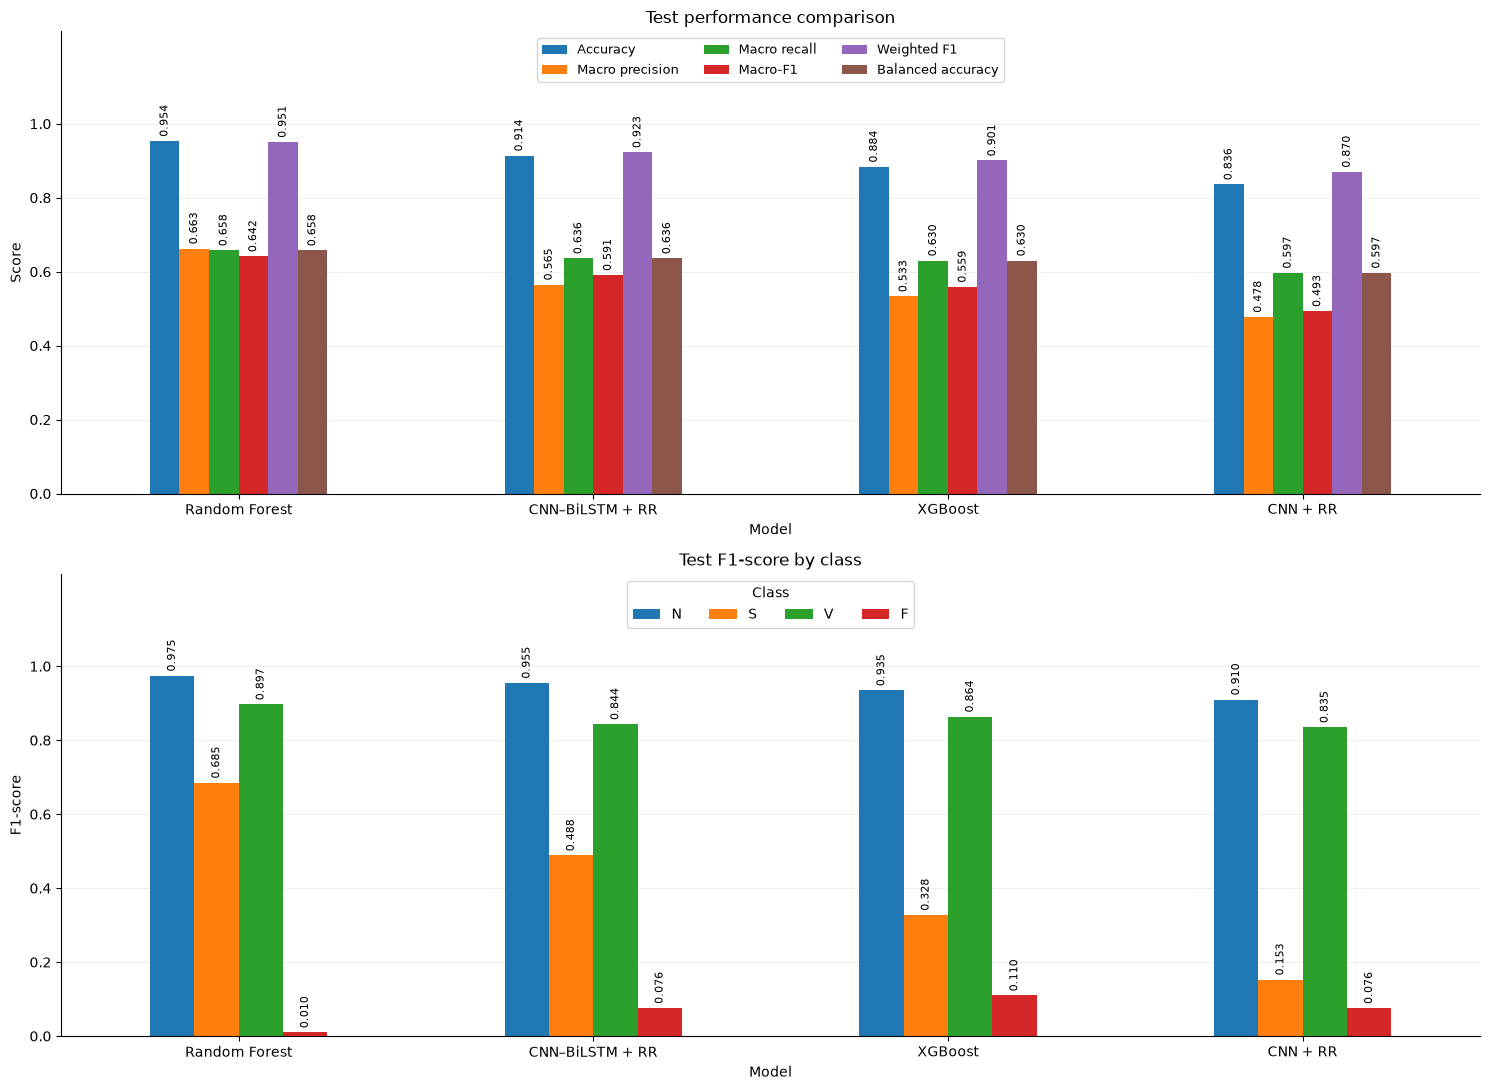

In [13]:
metric_labels = {'accuracy': 'Accuracy', 'precision_macro': 'Macro precision',
                 'recall_macro': 'Macro recall', 'macro_f1': 'Macro-F1',
                 'weighted_f1': 'Weighted F1', 'balanced_accuracy': 'Balanced accuracy'}
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
comparison.set_index('name')[list(metric_labels)].rename(columns=metric_labels).plot.bar(ax=axes[0])
axes[0].set(title='Test performance comparison', ylabel='Score', xlabel='Model', ylim=(0, 1.25))
axes[0].legend(loc='upper center', ncol=3, fontsize=9)
per_class = comparison.set_index('name')[[f'{label}_f1-score' for label in CLASSES]]
per_class.columns = CLASSES
per_class.plot.bar(ax=axes[1])
axes[1].set(title='Test F1-score by class', ylabel='F1-score', xlabel='Model', ylim=(0, 1.25))
axes[1].legend(title='Class', ncol=len(CLASSES), loc='upper center')
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8, rotation=90)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.tick_params(axis='x', rotation=0)
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(REPORTS / 'final' / 'comparison.png', dpi=160)
plt.show()
plt.close(fig)


## Test confusion matrices ? count and normalized
X = True class; Y = Predicted class. Normalization divides by the support of each true class before transposing, so each nonempty displayed column sums to 100%. Empty true classes are shown as zero.


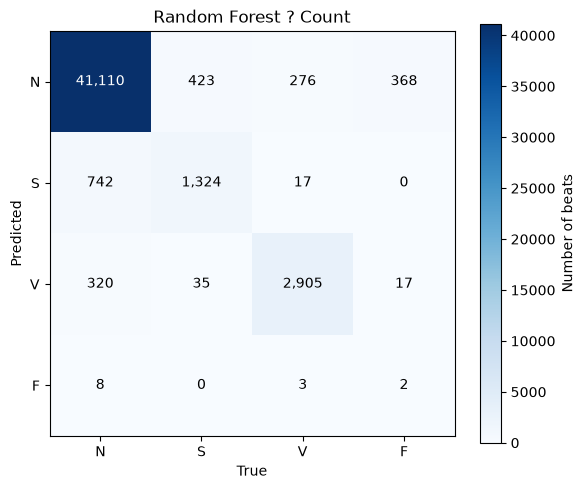

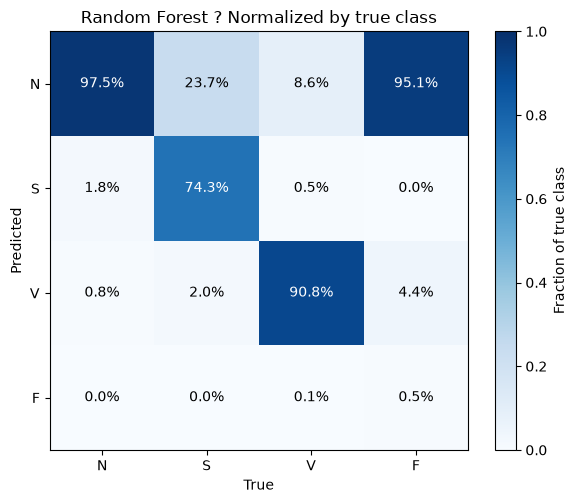

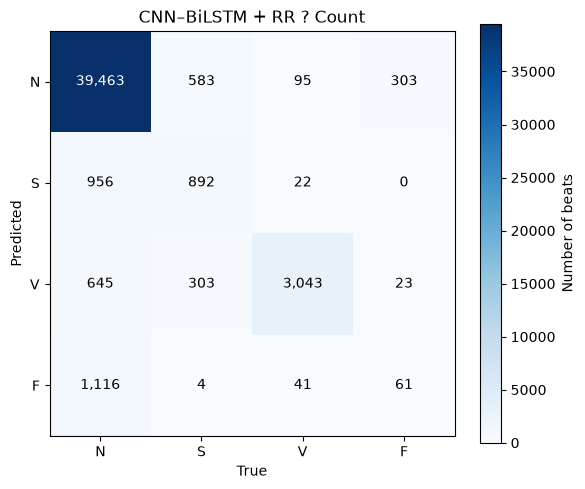

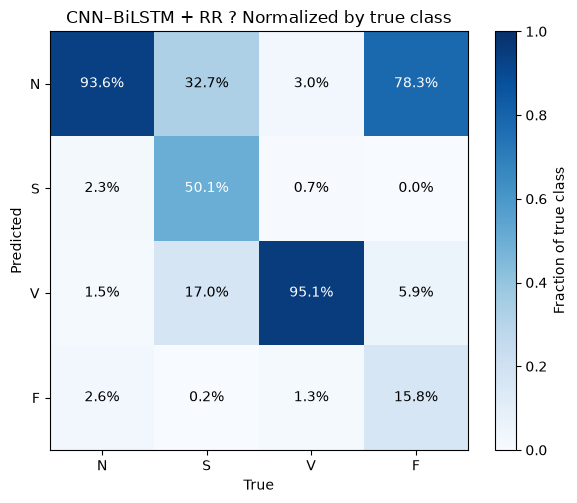

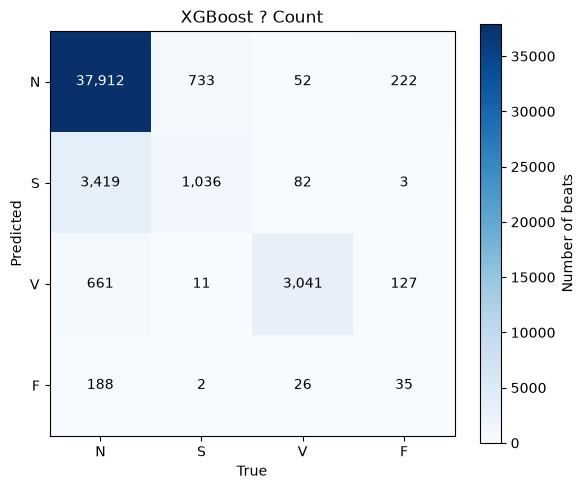

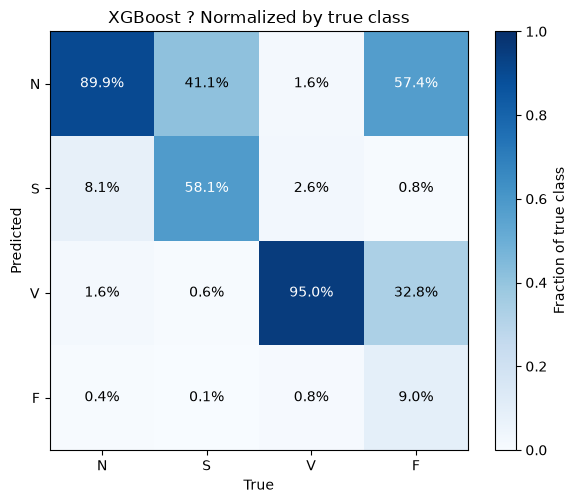

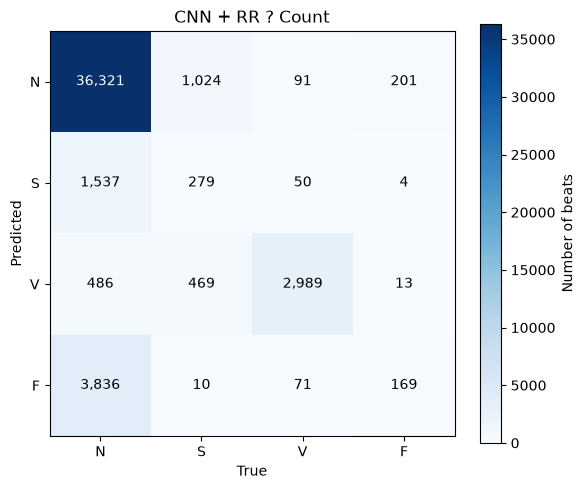

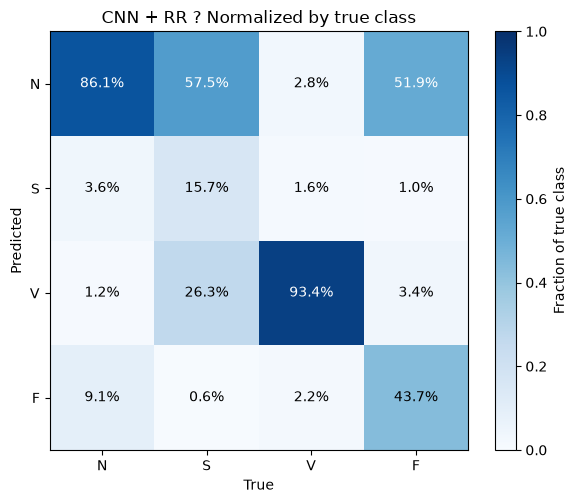

In [14]:
# Reuse saved metrics; no additional inference is needed to redraw these figures.
for row in comparison.itertuples(index=False):
    scores = read_json(REPORTS / 'final' / row.model / 'metrics.json')
    for normalized in [False, True]:
        fig = plot_confusion_matrix(scores, row.name, normalized=normalized)
        plt.show()
        plt.close(fig)
